# Коллапс мод: финальный эксперимент на Fashion-MNIST (3 сида)

In [ ]:
import os
import sys
import time
import json
from io import BytesIO
from pathlib import Path

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "src" / "toy8.py").exists())

# Переменные окружения для более быстрого обучения на видеокартах AMD (ROCm)
os.environ.setdefault("HSA_TOOLS_DISABLE_REGISTER", "1")
os.environ.setdefault("MIOPEN_FIND_MODE", "FAST")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
os.environ.setdefault("IPYTHONDIR", str(ROOT / ".jupyter"))
os.environ.setdefault("TORCH_HOME", str(ROOT / ".torch_home"))
os.environ.setdefault("MIOPEN_USER_DB_PATH", str(ROOT / ".miopen-db"))
os.environ.setdefault("MIOPEN_CUSTOM_CACHE_DIR", str(ROOT / ".miopen-cache"))
for _path in (os.environ["MPLCONFIGDIR"], os.environ["MIOPEN_USER_DB_PATH"],
              os.environ["MIOPEN_CUSTOM_CACHE_DIR"]):
    Path(_path).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

import ganlib as G
import toy8
import fid as FIDLIB


def show(fig):
    """Figure -> inline PNG; the notebook leaves nothing on disk from this."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


DEVICE = G.resolve_device()          # cuda on ROCm/CUDA, else mps, else cpu
print(G.device_report(DEVICE))
print(f"torch {torch.__version__}, HIP {torch.version.hip}, CUDA {torch.version.cuda}")
assert DEVICE.type == "cuda", "этот ноутбук рассчитан на GPU (ROCm или CUDA)"

SEEDS = [42, 43, 44] 
TOY_STEPS = 5000


(null): Success
(null): Success


AMD Radeon Graphics (ROCm/HIP 7.2.53211, 24 GiB, torch 2.14.1+rocm7.2)
torch 2.14.1+rocm7.2, HIP 7.2.53211, CUDA None


(null): Success
(null): Success


## 0. Синтетика: 8 гауссиан (проверить, что базовый эксперимент воспроизводится)

BCE покрывает 7.67 из 8 мод в среднем
(по сидам 8, 7, 8), WGAN-GP покрывает
6.33 из 8 (по сидам 3, 8, 8), крупнейшая мода —
0.240 ± 0.178, вне мод — 0.393 ± 0.402.
У реальных данных доля крупнейшей моды 0.133 при равномерных 1/8 = 0.125.

На синтетике разброс между сидами заметнее, чем на Fashion-MNIST: WGAN-GP покрывает по сидам 3, 8, 8 из 8, BCE — 8, 7, 8.

In [2]:
started = time.time()
toy = toy8.train_seeds(SEEDS, device=DEVICE, steps=TOY_STEPS, verbose=False)
toy_seconds = time.time() - started
print(f"синтетика: оба плеча на {len(SEEDS)} сидах за {toy_seconds:.0f} с")


toy8 seeds=[42, 43, 44]: AMD Radeon Graphics (ROCm/HIP 7.2.53211, 24 GiB, torch 2.14.1+rocm7.2)



=== seed 42: BCE ===



=== seed 42: WGAN-GP ===



=== seed 43: BCE ===



=== seed 43: WGAN-GP ===



=== seed 44: BCE ===



=== seed 44: WGAN-GP ===


синтетика: оба плеча на 3 сидах за 134 с


In [3]:
def cell(value, fmt="{:.3f}"):
    return fmt.format(value["mean"]) + " ± " + fmt.format(value["std"])

print(f"{'плечо':<9}{'покрыто мод':>16}{'топ-мода':>18}{'вне мод':>16}")
for arm in ("bce", "wgan_gp"):
    a = toy["arms"][arm]["agg"]
    print(f"{toy['arms'][arm]['display']:<9}{a['modes_covered']['mean']:>10.2f}/8   "
          f"{cell(a['max_mode_share']):>16}   {cell(a['outside_share']):>14}")
print("")
print("доля точек по модам, среднее ± std по сидам (порядок центров кольца):")
for arm in ("bce", "wgan_gp"):
    print(f"  {toy['arms'][arm]['display']:<9}" + " ".join(
        f"{value['mean']:.3f}" for value in toy["arms"][arm]["agg"]["share"]))
print(f"  {'реальные':<9}" + " ".join(f"{value:.3f}" for value in toy["real"]["stats"]["share"]))
print("")
for arm in ("bce", "wgan_gp"):
    print(f"  {toy['arms'][arm]['display']:<9} покрыто по сидам: "
          f"{', '.join(str(int(v)) for v in toy['arms'][arm]['agg']['modes_covered']['per_seed'])}")


плечо         покрыто мод          топ-мода         вне мод
BCE            7.67/8      0.238 ± 0.089    0.145 ± 0.067
WGAN-GP        6.33/8      0.240 ± 0.178    0.393 ± 0.402

доля точек по модам, среднее ± std по сидам (порядок центров кольца):
  BCE      0.159 0.102 0.096 0.173 0.095 0.093 0.078 0.204
  WGAN-GP  0.237 0.090 0.075 0.082 0.089 0.085 0.119 0.223
  реальные 0.133 0.129 0.123 0.117 0.117 0.129 0.125 0.126

  BCE       покрыто по сидам: 8, 7, 8
  WGAN-GP   покрыто по сидам: 3, 8, 8


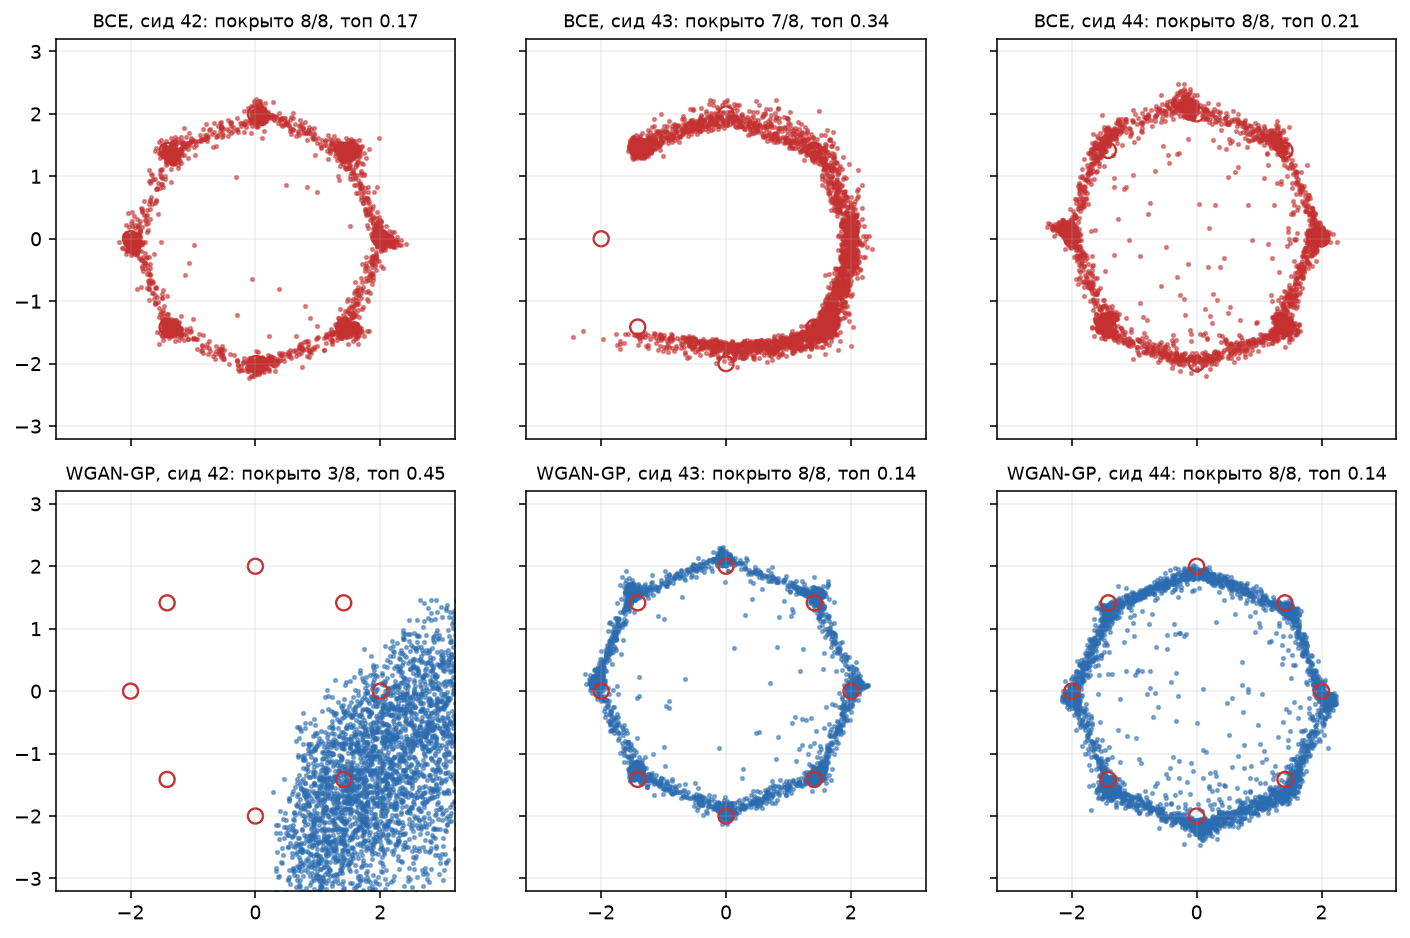

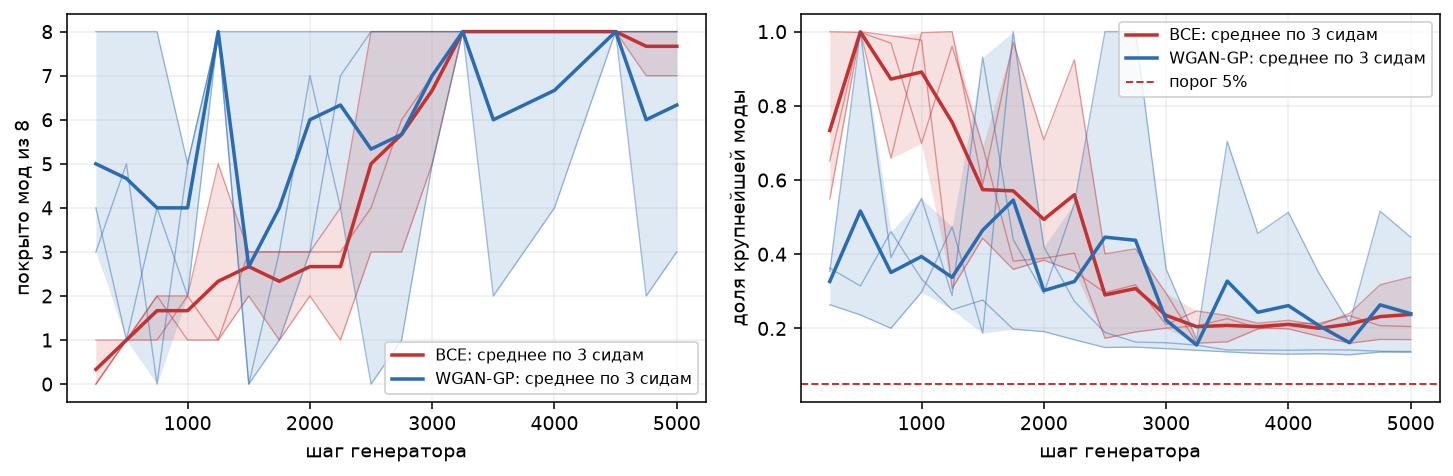

In [4]:
show(toy8.plot_seed_samples(toy))
show(toy8.plot_seed_curves(toy))


## 2. Fashion-MNIST: сравнение GAN и WGAN-GP

Архитектура одна, сравниваем BCE (`-log D(G(z))`) против WGAN-GP. Бюджет — 80 эпох, сиды
42, 43, 44.

Метрики мод считает замороженный разметчик из `artifacts/models/mode_classifier.pt`:
Критерий коллапса: доля топ-класса ≥ 0.35 **или** покрытие мод ≤ 0.75.

In [ ]:
# конфигурация
EPOCHS = 80        # эпох на плечо: одинаковый бюджет у BCE и у WGAN-GP
BATCH = 128
LR = 2e-4          # Adam, betas (0.5, 0.999), одинаковый шаг у D и у G
N_CRITIC = 5       # шагов критика на шаг генератора — как в основном ноутбуке
LAMBDA_GP = 10.0   # вес штрафа за градиент (только WGAN-GP)
D_WIDTHS = (128, 256, 256)   # каналы критика: два stride-2 (28→14→7) + stride-1 блок 7×7
G_WIDTHS = (128, 64)         # ширины генератора DCGAN
Z_DIM = 100
N_EVAL = 2048      # латентный банк, общий для всех сидов
EVAL_SEED = 2024   # сид этого банка (не сид обучения!)
COMPUTE_FID = True
RESUME = True      # продолжать прерванный прогон из artifacts/notebook_seeds
RUN_TAG = "run"    # каталог с чекпоинтами: artifacts/notebook_seeds_<tag>
N_CLUSTERS = 20    # кластеров в готовом k-means-референсе, переобучать не нужно

print(f"плечи: BCE и WGAN-GP, сиды {SEEDS}, по {EPOCHS} эпох каждое")
print(f"устройство: {G.device_report(DEVICE)}")


плечи: BCE и WGAN-GP, сиды [42, 43, 44], по 80 эпох каждое
устройство: AMD Radeon Graphics (ROCm/HIP 7.2.53211, 24 GiB, torch 2.14.1+rocm7.2)


In [6]:
import torch.nn as nn

CONV = G.conv2d_cls()          # FastConv2d на ROCm, nn.Conv2d на остальных устройствах


class Generator(nn.Module):
    """DCGAN-генератор из основного ноутбука: z(100) → 7×7 → 14×14 → 28×28, Tanh."""

    def __init__(self):
        super().__init__()
        w0, w1 = G_WIDTHS
        self.net = nn.Sequential(
            nn.ConvTranspose2d(Z_DIM, w0, 7, 1, 0), nn.BatchNorm2d(w0), nn.ReLU(True),
            nn.ConvTranspose2d(w0, w1, 4, 2, 1), nn.BatchNorm2d(w1), nn.ReLU(True),
            nn.ConvTranspose2d(w1, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    """Критик из основного ноутбука: два stride-2 блока (28→14→7) и stride-1 блок на 7×7."""

    def __init__(self):
        super().__init__()
        layers, width = [], 1
        for w in D_WIDTHS[:2]:
            layers += [CONV(width, w, 4, 2, 1), nn.LeakyReLU(0.2, True)]
            width = w
        for w in D_WIDTHS[2:]:
            layers += [CONV(width, w, 3, 1, 1), nn.LeakyReLU(0.2, True)]
            width = w
        layers += [nn.Flatten(), nn.Linear(width * 7 * 7, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def sample_z(n):
    return torch.randn(n, Z_DIM, 1, 1, device=DEVICE)


def gradient_penalty(critic, real, fake):
    """WGAN-GP: штраф на норму градиента критика вдоль отрезка real–fake."""
    alpha = torch.rand(real.size(0), 1, 1, 1, device=real.device)
    interp = (alpha * real + (1 - alpha) * fake).requires_grad_(True)
    score = critic(interp)
    grads = torch.autograd.grad(score, interp, torch.ones_like(score), create_graph=True)[0]
    return LAMBDA_GP * ((grads.flatten(1).norm(2, dim=1) - 1) ** 2).mean()


n_d, n_g = G.count_parameters(Critic()), G.count_parameters(Generator())
print(f"критик {n_d:,} параметров, генератор {n_g:,}, D/G = {n_d / n_g:.3f}".replace(",", " "))
print(f"свёртки критика: {CONV.__name__}")


критик 1 129 345 параметров  генератор 759 873  D/G = 1.486
свёртки критика: FastConv2d


In [ ]:
import json
import time

ART = ROOT / "artifacts"
RUN_DIR = ART / f"notebook_seeds_{RUN_TAG}"
REF_BCE80 = ART / "fashion" / "fashion_strongD_80ep" / "metrics" / "fashion_strongD_80ep_history.json"
REF_WGAN = ART / "fashion" / "fashion_strongD_wgan" / "metrics" / "fashion_strongD_wgan_history.json"
RUN_DIR.mkdir(parents=True, exist_ok=True)

CLF = G.ModeClassifier()
CLF.load_state_dict(torch.load(ART / "models" / "mode_classifier.pt", map_location="cpu",
                               weights_only=True)["state_dict"])
CLF.eval()
_blob = np.load(ART / "metrics" / "real_reference.npz")
REF = {"centers": _blob["centers"], "feature_mean": _blob["feature_mean"],
       "feature_std": _blob["feature_std"],
       "dist_threshold": float(_blob["dist_threshold"])}

X = G.load_train_tensor(G.Config(dataset="fashion")).to(DEVICE)
ITERS = X.size(0) // BATCH
# общий латентный банк: сиды отличаются моделью, а не точками, на которых их меряют
Z_EVAL = torch.randn(N_EVAL, Z_DIM, 1, 1, device=DEVICE,
                     generator=torch.Generator(device=DEVICE).manual_seed(EVAL_SEED))
print(f"данные {tuple(X.shape)} на {DEVICE}, {ITERS} итераций в эпохе")

if COMPUTE_FID and RUN_TAG == "run":
    INCEPTION = FIDLIB.make_inception(DEVICE)
    _real = np.load(FIDLIB.STATS_DIR / f"real_fashion_a_n{FIDLIB.N_SAMPLES}_2048d.npz")
    REAL_MU, REAL_SIGMA = _real["mu"], _real["sigma"].astype(np.float64)
    print("FID: InceptionV3 загружен, эталон тестовой части прочитан")
else:
    INCEPTION = None
    REAL_MU = REAL_SIGMA = None

HISTORY_KEYS = ("epoch", "max_class_share", "mode_coverage", "class_entropy",
                "intra_class_spread", "d_margin", "seconds", "loss_g", "loss_d",
                "class_share")


def run_path(arm, seed):
    return RUN_DIR / f"{arm}_seed{seed}"


def arm_done(arm, seed, epochs):
    """Совсем готовый прогон: история нужной длины и финальные сэмплы с FID."""
    metrics = run_path(arm, seed) / "metrics.json"
    final = run_path(arm, seed) / "final.pt"
    if not (metrics.exists() and final.exists()):
        return None
    history = json.loads(metrics.read_text())
    if len(history["epoch"]) < epochs or "fid" not in history:
        return None
    blob = torch.load(final, map_location="cpu", weights_only=False)
    total = float(history.get("total_seconds", history["seconds"][-1]))
    return {"history": history, "final64": blob["final64"], "fid": float(history["fid"]),
            "seconds": total, "gen": None}


def train_arm(arm, epochs, seed):
    """Одно плечо с нуля на заданном сиде. Каждую эпоху пишет метрики и чекпоинт."""
    done = arm_done(arm, seed, epochs) if RESUME else None
    if done is not None:
        print(f"[{arm} сид {seed}] уже обучено на {epochs} эпох — читаю с диска")
        return done
    with open(RUN_DIR / "progress.log", "a") as handle:
        handle.write(f"[{arm} сид {seed}] старт\n")

    path = run_path(arm, seed)
    path.mkdir(parents=True, exist_ok=True)
    metrics_path = path / "metrics.json"
    state_path = path / "state.pt"

    G.set_seed(seed)
    gen, disc = Generator().to(DEVICE), Critic().to(DEVICE)
    opt_g = torch.optim.Adam(gen.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(disc.parameters(), lr=LR, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()

    history = {key: [] for key in HISTORY_KEYS}
    start, started = 1, time.time()
    if RESUME and state_path.exists() and metrics_path.exists():
        blob = torch.load(state_path, map_location=DEVICE, weights_only=False)
        gen.load_state_dict(blob["gen"])
        disc.load_state_dict(blob["disc"])
        opt_g.load_state_dict(blob["opt_g"])
        opt_d.load_state_dict(blob["opt_d"])
        torch.set_rng_state(blob["rng_cpu"])
        torch.cuda.set_rng_state(blob["rng_cuda"].cpu())
        history = json.loads(metrics_path.read_text())
        start = int(blob["epoch"]) + 1
        print(f"[{arm} сид {seed}] продолжаю с эпохи {start}")

    for epoch in range(start, epochs + 1):
        t0 = time.time()
        gen.train()
        disc.train()
        log = {"loss_g": [], "loss_d": [], "d_margin": []}
        perm = torch.randperm(X.size(0), device=DEVICE)
        for step in range(ITERS):
            real = X[perm[step * BATCH:(step + 1) * BATCH]]
            z = sample_z(BATCH)
            if arm == "bce":                              # обычный GAN, non-saturating
                fake = gen(z).detach()
                out_real, out_fake = disc(real), disc(fake)
                loss_d = (bce(out_real, torch.ones_like(out_real))
                          + bce(out_fake, torch.zeros_like(out_fake)))
                opt_d.zero_grad()
                loss_d.backward()
                opt_d.step()
                log["loss_d"].append(loss_d.item())
                log["d_margin"].append(out_real.mean().item() - out_fake.mean().item())
                if (step + 1) % N_CRITIC == 0:
                    out_g = disc(gen(sample_z(BATCH)))
                    loss_g = bce(out_g, torch.ones_like(out_g))
                    opt_g.zero_grad()
                    loss_g.backward()
                    opt_g.step()
                    log["loss_g"].append(loss_g.item())
            else:                                         # WGAN-GP: критик и штраф
                real = real.requires_grad_(False)
                with torch.no_grad():
                    fake = gen(z)
                d_real, d_fake = disc(real), disc(fake)
                gp = gradient_penalty(disc, real, fake)
                loss_d = d_fake.mean() - d_real.mean() + gp
                opt_d.zero_grad()
                loss_d.backward()
                opt_d.step()
                log["loss_d"].append((d_fake.mean() - d_real.mean()).item())
                log["d_margin"].append(d_real.mean().item() - d_fake.mean().item())
                if (step + 1) % N_CRITIC == 0:
                    loss_g = -disc(gen(sample_z(BATCH))).mean()
                    opt_g.zero_grad()
                    loss_g.backward()
                    opt_g.step()
                    log["loss_g"].append(loss_g.item())

        modes = G.measure_modes(gen, Z_EVAL, CLF, REF, N_CLUSTERS)   # 2048 сэмплов
        seconds = time.time() - t0
        history["epoch"].append(epoch)
        history["max_class_share"].append(modes["max_class_share"])
        history["mode_coverage"].append(modes["mode_coverage"])
        history["class_entropy"].append(modes["class_entropy"])
        history["intra_class_spread"].append(modes["intra_class_spread"])
        history["d_margin"].append(float(np.mean(log["d_margin"])))
        history["seconds"].append(seconds)
        history["class_share"].append([float(share) for share in modes["class_share"]])
        history["loss_d"].append(float(np.mean(log["loss_d"])))
        history["loss_g"].append(float(np.mean(log["loss_g"])) if log["loss_g"]
                                 else float("nan"))
        history["total_seconds"] = time.time() - started
        metrics_path.write_text(json.dumps(history))
        if epoch % 5 == 0 or epoch == epochs:
            torch.save({"gen": gen.state_dict(), "disc": disc.state_dict(),
                        "opt_g": opt_g.state_dict(), "opt_d": opt_d.state_dict(),
                        "epoch": epoch, "rng_cpu": torch.get_rng_state(),
                        "rng_cuda": torch.cuda.get_rng_state()}, state_path)
        line = (f"[{arm} сид {seed}] эпоха {epoch:02d}/{epochs}: доля топ "
                f"{modes['max_class_share']:.3f}, H {modes['class_entropy']:.3f}, покрытие "
                f"{modes['mode_coverage']:.2f}, {seconds:.0f} с")
        print(line, flush=True)
        with open(RUN_DIR / "progress.log", "a") as handle:
            handle.write(line + "\n")

    gen.eval()
    with torch.no_grad():
        snap = G.generate_samples(gen, Z_EVAL[:64])
    final64 = ((snap.cpu() * 0.5 + 0.5).clamp(0, 1).mul(255).byte().squeeze(1).numpy())
    torch.save({"final64": final64}, path / "final.pt")

    if INCEPTION is not None:
        z = FIDLIB.latent(FIDLIB.N_SAMPLES, Z_DIM).to(DEVICE)
        with torch.no_grad():
            batches = [gen(z[i:i + FIDLIB.BATCH])
                       for i in range(0, len(z), FIDLIB.BATCH)]
            mu, sigma = FIDLIB.stats_of(
                FIDLIB.features_of_batches(batches, INCEPTION, DEVICE))
        history["fid"] = float(FIDLIB.frechet_distance(mu, sigma, REAL_MU, REAL_SIGMA))
    else:
        history["fid"] = float("nan")
    metrics_path.write_text(json.dumps(history))
    print(f"[{arm} сид {seed}] готово: {history['total_seconds']:.0f} с, "
          f"FID {history['fid']:.1f}", flush=True)
    with open(RUN_DIR / "progress.log", "a") as handle:
        handle.write(f"[{arm} сид {seed}] готово: {history['total_seconds']:.0f} с, "
                     f"FID {history['fid']:.1f}\n")
    return {"history": history, "final64": final64, "fid": history["fid"],
            "seconds": history["total_seconds"], "gen": gen}


RUNS = {}
for _seed in SEEDS:
    for _arm in ("wgan_gp", "bce"):   
        RUNS[(_arm, _seed)] = train_arm(_arm, EPOCHS, _seed)

print("")
print(f"обучение завершено: {sum(run['seconds'] for run in RUNS.values()) / 60:.0f} мин "
      f"на {len(SEEDS)} сидов")


данные (60000, 1, 28, 28) на cuda, 468 итераций в эпохе


FID: InceptionV3 загружен, эталон тестовой части прочитан


[wgan_gp сид 42] эпоха 01/80: доля топ 0.256, H 0.922, покрытие 0.75, 12 с


MIOpen(HIP): Warning [IsEnoughWorkspace] [GetSolutionsFallback AI] Solver <GemmBwdRest>, workspace required: 25088, provided ptr: 0 size: 0


[wgan_gp сид 42] эпоха 02/80: доля топ 0.215, H 0.969, покрытие 0.90, 12 с


[wgan_gp сид 42] эпоха 03/80: доля топ 0.176, H 0.988, покрытие 0.95, 12 с


... (482 outputs left out)

[bce сид 44] эпоха 79/80: доля топ 0.404, H 0.670, покрытие 0.60, 6 с


[bce сид 44] эпоха 80/80: доля топ 0.401, H 0.672, покрытие 0.65, 6 с


[bce сид 44] готово: 519 с, FID 73.5



обучение завершено: 73 мин на 3 сидов


In [8]:
def final(arm, seed, key):
    return float(RUNS[(arm, seed)]["history"][key][-1])


def spread(values, fmt="{:.3f}"):
    values = list(values)
    mean = sum(values) / len(values)
    std = (sum((v - mean) ** 2 for v in values) / (len(values) - 1)) ** 0.5 \
        if len(values) > 1 else 0.0
    return f"{fmt.format(mean)} ± {fmt.format(std)}"


def fired(history):
    return [epoch for epoch, top, cov in zip(
        history["epoch"], history["max_class_share"], history["mode_coverage"])
        if top >= 0.35 or cov <= 0.75]


print("по каждому сиду отдельно (финальная эпоха):")
print(f"{'плечо':<8}{'сид':>5}{'доля топ':>10}{'покрытие':>10}{'H':>7}{'intra':>7}"
      f"{'margin':>8}{'FID':>7}{'эпох с коллапсом':>19}")
for arm in ("bce", "wgan_gp"):
    for seed in SEEDS:
        h = RUNS[(arm, seed)]["history"]
        print(f"{arm:<8}{seed:>5}{h['max_class_share'][-1]:>10.3f}"
              f"{h['mode_coverage'][-1]:>10.2f}{h['class_entropy'][-1]:>7.3f}"
              f"{h['intra_class_spread'][-1]:>7.2f}{h['d_margin'][-1]:>8.2f}"
              f"{h['fid']:>7.1f}{len(fired(h)):>9}/{len(h['epoch']):<5}")

print("")
print("среднее ± std по сидам (финальная эпоха):")
print(f"{'плечо':<8}{'доля топ':>18}{'покрытие':>16}{'H':>16}{'FID':>16}")
for arm in ("bce", "wgan_gp"):
    top = spread(final(arm, s, "max_class_share") for s in SEEDS)
    cov = spread((final(arm, s, "mode_coverage") for s in SEEDS), "{:.2f}")
    ent = spread((final(arm, s, "class_entropy") for s in SEEDS))
    fid = spread((RUNS[(arm, s)]["fid"] for s in SEEDS), "{:.1f}")
    print(f"{arm:<8}{top:>18}{cov:>16}{ent:>16}{fid:>16}")

print("")
print("критерий коллапса (доля топ ≥ 0.35 или покрытие ≤ 0.75):")
for arm in ("bce", "wgan_gp"):
    shares = [len(fired(RUNS[(arm, s)]["history"])) / len(RUNS[(arm, s)]["history"]["epoch"])
              for s in SEEDS]
    finals = [bool(fired(RUNS[(arm, s)]["history"])) and
              fired(RUNS[(arm, s)]["history"])[-1] == EPOCHS for s in SEEDS]
    print(f"  {arm:<8} на финальной эпохе — {sum(finals)} из {len(SEEDS)} сидов; "
          f"доля эпох с критерием {spread(shares, '{:.2f}')}")

# эталон основного ноутбука для контекста
ref_bce = json.loads(REF_BCE80.read_text()) if REF_BCE80.exists() else None
ref_wgan = json.loads(REF_WGAN.read_text()) if REF_WGAN.exists() else None
if ref_bce or ref_wgan:
    print("")
    print("для контекста — эталон основного ноутбука (MPS, один сид 42):")
    fid_ref = json.loads((ART / "metrics" / "fid_fashion_factorial.json").read_text())["arms"]
    if ref_bce:
        print(f"  BCE, 80 эпох: топ {ref_bce['max_class_share'][-1]:.3f}, "
              f"покрытие {ref_bce['mode_coverage'][-1]:.2f}, "
              f"FID {fid_ref['fashion_strongD_80ep']['fid']:.1f}")
    if ref_wgan:
        print(f"  WGAN-GP, 40 эпох: топ {ref_wgan['max_class_share'][-1]:.3f}, "
              f"покрытие {ref_wgan['mode_coverage'][-1]:.2f}, "
              f"FID {fid_ref['fashion_strongD_wgan']['fid']:.1f}")

# сводка для прозы и для artifacts/notebook_seeds/run.json
summary = {
    "config": {"EPOCHS": EPOCHS, "SEEDS": list(SEEDS), "BATCH": BATCH, "LR": LR,
               "N_CRITIC": N_CRITIC, "LAMBDA_GP": LAMBDA_GP,
               "D_WIDTHS": list(D_WIDTHS), "G_WIDTHS": list(G_WIDTHS), "Z_DIM": Z_DIM,
               "N_EVAL": N_EVAL, "EVAL_SEED": EVAL_SEED, "device": DEVICE.type},
    "device": G.device_report(DEVICE),
    "torch": torch.__version__, "hip": torch.version.hip,
    "arms": {arm: {"seeds": {str(seed): {
        "history": RUNS[(arm, seed)]["history"],
        "fid": RUNS[(arm, seed)]["fid"],
        "seconds": RUNS[(arm, seed)]["seconds"]} for seed in SEEDS}}
        for arm in ("bce", "wgan_gp")},
}
(RUN_DIR / "run.json").write_text(json.dumps(summary, indent=1))
print("")
print(f"записано {(RUN_DIR / 'run.json').relative_to(ROOT)}")


по каждому сиду отдельно (финальная эпоха):
плечо     сид  доля топ  покрытие      H  intra  margin    FID   эпох с коллапсом
bce        42     0.431      0.65  0.665  13.96   23.80   84.6       56/80   
bce        43     0.337      0.75  0.825  14.48   18.46   79.0       79/80   
bce        44     0.401      0.65  0.672  13.94   26.31   73.5       51/80   
wgan_gp    42     0.120      1.00  0.998  18.78    2.42   31.2        1/80   
wgan_gp    43     0.136      1.00  0.994  18.85    2.39   29.8        0/80   
wgan_gp    44     0.127      1.00  0.996  18.68    2.40   32.0        0/80   

среднее ± std по сидам (финальная эпоха):
плечо             доля топ        покрытие               H             FID
bce          0.390 ± 0.048     0.68 ± 0.06   0.721 ± 0.091      79.1 ± 5.6
wgan_gp      0.128 ± 0.008     1.00 ± 0.00   0.996 ± 0.002      31.0 ± 1.1

критерий коллапса (доля топ ≥ 0.35 или покрытие ≤ 0.75):
  bce      на финальной эпохе — 3 из 3 сидов; доля эпох с критерием 0.78 ± 0.19


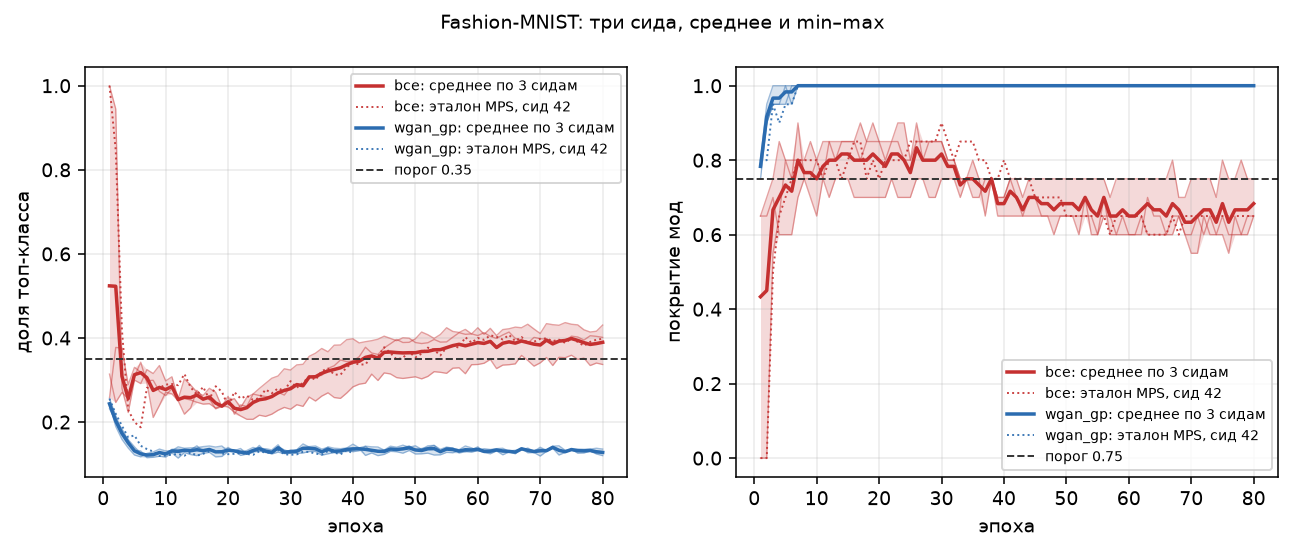

In [9]:
COLORS = {"bce": "#c53030", "wgan_gp": "#2b6cb0"}

refs = {"bce": json.loads(REF_BCE80.read_text()) if REF_BCE80.exists() else None,
        "wgan_gp": json.loads(REF_WGAN.read_text()) if REF_WGAN.exists() else None}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for arm in ("bce", "wgan_gp"):
    histories = [RUNS[(arm, seed)]["history"] for seed in SEEDS]
    epochs = histories[0]["epoch"]
    for key, ax, reference in (("max_class_share", axes[0], refs[arm]),
                               ("mode_coverage", axes[1], refs[arm])):
        values = np.array([h[key] for h in histories], dtype=float)
        ax.plot(epochs, values.mean(0), color=COLORS[arm], linewidth=1.8,
                label=f"{arm}: среднее по {len(SEEDS)} сидам")
        ax.fill_between(epochs, values.min(0), values.max(0), color=COLORS[arm],
                        alpha=0.18, linewidth=0)
        for history in histories:
            ax.plot(history["epoch"], history[key], color=COLORS[arm],
                    linewidth=0.7, alpha=0.45)
        if reference is not None:
            ax.plot(reference["epoch"], reference[key], color=COLORS[arm],
                    linestyle=":", linewidth=1.0, alpha=0.9,
                    label=f"{arm}: эталон MPS, сид 42")
axes[0].set_ylabel("доля топ-класса")
axes[1].set_ylabel("покрытие мод")
axes[0].axhline(0.35, color="#333333", linestyle="--", linewidth=1, label="порог 0.35")
axes[1].axhline(0.75, color="#333333", linestyle="--", linewidth=1, label="порог 0.75")
for ax in axes:
    ax.set_xlabel("эпоха")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.suptitle("Fashion-MNIST: три сида, среднее и min–max", fontsize=10)
show(fig)


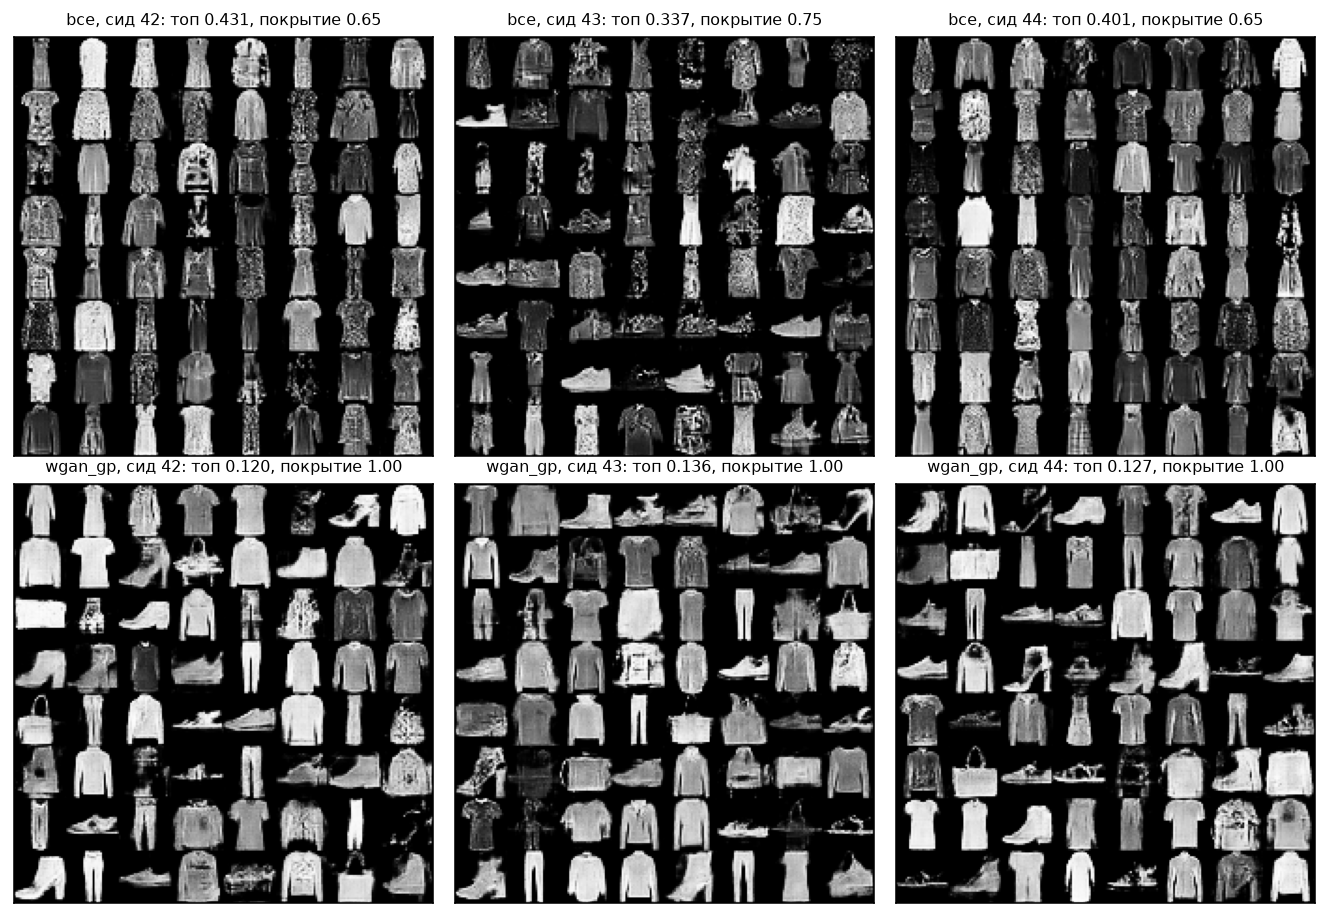

In [10]:
def tile(images):
    """64 сэмпла (8x8) -> одна картинка 224x224."""
    return images.reshape(8, 8, 28, 28).transpose(0, 2, 1, 3).reshape(8 * 28, 8 * 28)


fig, axes = plt.subplots(2, len(SEEDS), figsize=(3.2 * len(SEEDS), 6.6))
for row, arm in enumerate(("bce", "wgan_gp")):
    for col, seed in enumerate(SEEDS):
        ax = axes[row][col]
        h = RUNS[(arm, seed)]["history"]
        ax.imshow(tile(RUNS[(arm, seed)]["final64"]), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{arm}, сид {seed}: топ {h['max_class_share'][-1]:.3f}, "
                     f"покрытие {h['mode_coverage'][-1]:.2f}", fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
fig.tight_layout()
show(fig)


Таким образом, коллапс мод можно наблюдать и визуально: после обучения обычного GAN на 80 эпохах, разнообразие классов снизилось (например, в генерации очень мало штанов и обуви, а также цвет, т.е. яркость, изображений, почти у всех изображений одинакова и в среднем темнее), в то время как при обучении GAN с градиентным штрафом на том же числе эпох, в генерации встречаются все классы и распределены они более равномерно.

## Выводы из эксперимента

* **BCE, 80 эпох.** Критерий коллапса на финальной эпохе выполнен у 3 из 3 сидов.
* **WGAN-GP, 80 эпох.** Критерий на финальной эпохе — у 0 из 3 сидов.
* **Разброс между сидами.** У BCE стандартное отклонение доли топ-класса больше, чем у WGAN-GP, а покрытие меньше:
  разрыв между функциями потерь больше, чем разброс между сидами внутри одного класса моделей => коллапс мод - следствие функции потерь.
* **Внутриклассовый разброс** (насколько разнообразны картинки внутри доминирующего класса):
  BCE 14.1 ± 0.3, WGAN-GP 18.8 ± 0.1. Это подтверждается и визуально.
* **Время.** Один прогон BCE — 519 с, один прогон WGAN-GP — 942 с (+81,5 %).
* **Вывод.** При равных условиях WGAN-GP на Fashion-MNIST сохранил все моды и предотвратил дисбаланс классов при генерации, при этом он устойчив при обучениии на большом числе эпох.


In [11]:
for path in sorted(RUN_DIR.iterdir()):
    print(path.relative_to(ROOT))
print("")
print("каждый прогон лежит в своей папке: metrics.json (история по эпохам),")
print("state.pt (последний чекпоинт), final.pt (сэмплы финальной эпохи).")


artifacts/notebook_seeds_run/bce_seed42
artifacts/notebook_seeds_run/bce_seed43
artifacts/notebook_seeds_run/bce_seed44
artifacts/notebook_seeds_run/progress.log
artifacts/notebook_seeds_run/run.json
artifacts/notebook_seeds_run/wgan_gp_seed42
artifacts/notebook_seeds_run/wgan_gp_seed43
artifacts/notebook_seeds_run/wgan_gp_seed44

каждый прогон лежит в своей папке: metrics.json (история по эпохам),
state.pt (последний чекпоинт), final.pt (сэмплы финальной эпохи).
